# Part 2: Test popular claims

Four popular claims about F1, each checked with a shuffle test: if the effect were only luck, how often would shuffled data show one this big? Below 5% counts as probably real. Reads `data/processed/results_joined.csv` (run `01_build_dataset.ipynb` first) and `data/raw/pit_stops.csv`. The findings table is at the end.

## 2.1 Does grid position matter more at Monaco than at other tracks?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/results_joined.csv", low_memory=False)
# Leave out the Indianapolis 500 (1950-1960): it counted for the championship,
# but it was a separate American race with its own drivers
df = df[~df["indy500"]].copy()

df["circuit"].value_counts().head(10)

circuit
Autodromo Nazionale di Monza    1754
Circuit de Monaco               1508
Silverstone Circuit             1407
Circuit de Spa-Francorchamps    1259
Circuit Gilles Villeneuve       1026
Nürburgring                      953
Autódromo José Carlos Pace       926
Hungaroring                      911
Red Bull Ring                    910
Hockenheimring                   861
Name: count, dtype: int64

In [2]:
# Same filter as 1.4: finishers who started from a real grid spot
finishers = df[df["finished"] & (df["grid"] > 0)].copy()

# New column: True for rows at Monaco, False for every other track
finishers["is_monaco"] = finishers["circuit"] == "Circuit de Monaco"

# Same "link" score as 1.4: grid and finish ranked within each race (1 = the same order in every race)
finishers["grid_rank"] = finishers.groupby("raceId")["grid"].rank()
finishers["finish_rank"] = finishers.groupby("raceId")["position"].rank()

def grid_finish_link(d):
    return d["grid_rank"].corr(d["finish_rank"])

finishers.groupby("is_monaco").apply(grid_finish_link).round(2)

is_monaco
False    0.78
True     0.79
dtype: float64

In [3]:
rng = np.random.default_rng(42)  # random number maker; 42 = same "random" result every run

# The real gap: Monaco's link minus everyone else's
observed_gap = grid_finish_link(finishers[finishers["is_monaco"]]) - grid_finish_link(finishers[~finishers["is_monaco"]])

race_ids = finishers["raceId"].unique()                                # every race ID once
n_monaco = finishers.loc[finishers["is_monaco"], "raceId"].nunique()   # how many Monaco races (72)

fake_gaps = []
for i in range(1000):
    fake_races = rng.choice(race_ids, size=n_monaco, replace=False)  # pick 72 random races
    in_fake = finishers["raceId"].isin(fake_races)                   # True for rows in those races
    gap = grid_finish_link(finishers[in_fake]) - grid_finish_link(finishers[~in_fake])
    fake_gaps.append(gap)

fake_gaps = np.array(fake_gaps)
share = (np.abs(fake_gaps) >= abs(observed_gap)).mean()

print(f"Real Monaco gap: {observed_gap:.3f}")
print(f"Random groups of {n_monaco} races had a gap this big or bigger {share:.0%} of the time")

Real Monaco gap: 0.013
Random groups of 72 races had a gap this big or bigger 53% of the time


In [4]:
# Front of the grid: does the pole sitter win more often at Monaco?
rng = np.random.default_rng(42)  # fresh random maker so this cell gives the same result every run

# One row per race: shared cars give a few 1950s races 2-3 pole rows (same fix as 1.1)
poles = df[df["pole"]].groupby(["raceId", "circuit"])["won"].any().reset_index()
poles["is_monaco"] = poles["circuit"] == "Circuit de Monaco"

monaco_rate = poles.loc[poles["is_monaco"], "won"].mean()   # share of Monaco poles that became wins
other_rate = poles.loc[~poles["is_monaco"], "won"].mean()   # same for every other track
observed_pole_gap = monaco_rate - other_rate

pole_race_ids = poles["raceId"].unique()
n_monaco_poles = poles.loc[poles["is_monaco"], "raceId"].nunique()

fake_pole_gaps = []
for i in range(1000):
    fake_races = rng.choice(pole_race_ids, size=n_monaco_poles, replace=False)  # 72 random "fake Monacos"
    in_fake = poles["raceId"].isin(fake_races)
    fake_pole_gaps.append(poles.loc[in_fake, "won"].mean() - poles.loc[~in_fake, "won"].mean())

fake_pole_gaps = np.array(fake_pole_gaps)
pole_share = (np.abs(fake_pole_gaps) >= abs(observed_pole_gap)).mean()

print(f"Pole sitter won at Monaco: {monaco_rate:.0%}, elsewhere: {other_rate:.0%}")
print(f"Random groups of {n_monaco_poles} races had a gap this big or bigger {pole_share:.0%} of the time")

Pole sitter won at Monaco: 47%, elsewhere: 44%
Random groups of 72 races had a gap this big or bigger 61% of the time


Among cars that finished, the link between starting and finishing position at Monaco (0.79) is almost the same as at other tracks (0.78). A shuffle test found that random groups of 72 races show a gap this big or bigger 53% of the time, so the difference is easily explained by chance. The front of the grid tells the same story: pole sitters won 47% of the time at Monaco and 44% elsewhere, but random groups of 72 races show a gap that big or bigger 61% of the time. This data doesn't support the claim that grid position matters more at Monaco.

## 2.2 Have pit stops gotten meaningfully faster, beyond fractions of a second?

In [5]:
# Pit stop data only covers 2011 onwards, so it's in its own file
pits = pd.read_csv("../data/raw/pit_stops.csv")
races = pd.read_csv("../data/raw/races.csv")
circuits = pd.read_csv("../data/raw/circuits.csv")

# Add the year and track name to each stop
pits = pits.merge(races[["raceId", "year", "circuitId"]], on="raceId")
pits = pits.merge(circuits[["circuitId", "name"]].rename(columns={"name": "circuit"}), on="circuitId")

# Time from pit entry to pit exit, in seconds
# (use "milliseconds", not "duration": "duration" is stored as text for very long stops)
pits["seconds"] = pits["milliseconds"] / 1000

pits["seconds"].describe()

count    12971.000000
mean        89.241324
std        324.925485
min         12.092000
25%         21.906000
50%         23.609000
75%         26.708500
max       3069.017000
Name: seconds, dtype: float64

In [6]:
normal = pits[pits["seconds"] <= 60].copy()

print(f"Kept {len(normal)} of {len(pits)} stops")
normal["seconds"].describe()

Kept 12360 of 12971 stops


count    12360.000000
mean        24.414390
std          4.693933
min         12.092000
25%         21.831750
50%         23.423000
75%         25.676500
max         59.555000
Name: seconds, dtype: float64

In [7]:
# One number per race: the typical (median) stop time in that race
race_medians = normal.groupby(["raceId", "year", "circuit"])["seconds"].median().reset_index()

# Keep tracks with at least 5 seasons of data, so each track has a fair "usual" time
seasons_per_track = race_medians.groupby("circuit")["year"].transform("nunique")
race_medians = race_medians[seasons_per_track >= 5].copy()

# Each race vs. its own track's usual time (negative = faster than usual for that track)
track_usual = race_medians.groupby("circuit")["seconds"].transform("median")
race_medians["vs_usual"] = race_medians["seconds"] - track_usual

# The typical difference for each season
yearly = race_medians.groupby("year")["vs_usual"].median()
yearly.round(2)

year
2011   -1.42
2012   -1.68
2013    0.00
2014    0.34
2015    0.31
2016    0.02
2017   -0.02
2018   -0.03
2019   -0.06
2020    0.00
2021   -0.18
2022    0.21
2023    0.16
2024   -0.04
2025   -0.18
2026    0.38
Name: vs_usual, dtype: float64

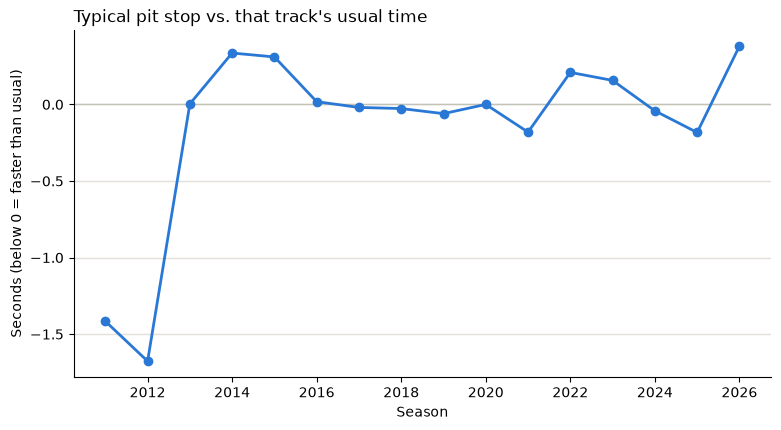

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axhline(0, color="#c3c2b7", linewidth=1)   # 0 = that track's usual time
ax.plot(yearly.index, yearly.values, color="#2a78d6", linewidth=2, marker="o", markersize=6)
ax.set_title("Typical pit stop vs. that track's usual time", loc="left")
ax.set_xlabel("Season")
ax.set_ylabel("Seconds (below 0 = faster than usual)")
ax.grid(axis="y", color="#e1e0d9", linewidth=1)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [9]:
rng = np.random.default_rng(42)  # same "random" result every run

# Only seasons after the 2013-2014 jump, split into an earlier and a recent half
stable = race_medians[race_medians["year"] >= 2014].copy()
stable["recent"] = stable["year"] >= 2020

# Gap between the typical recent race and the typical 2014-2019 race (negative = recent is faster)
def era_gap(d):
    return d.loc[d["recent"], "vs_usual"].median() - d.loc[~d["recent"], "vs_usual"].median()

observed_era_gap = era_gap(stable)

# "Recent" belongs to a whole season, so shuffle seasons, not single races (like the random groups of races in 2.1)
seasons = stable["year"].unique()
n_recent = stable.loc[stable["recent"], "year"].nunique()  # 7 recent seasons (2020-2026)

fake_era_gaps = []
for i in range(1000):
    fake_recent = rng.choice(seasons, size=n_recent, replace=False)  # pick 7 random seasons to call "recent"
    shuffled = stable.copy()
    shuffled["recent"] = shuffled["year"].isin(fake_recent)
    fake_era_gaps.append(era_gap(shuffled))

fake_era_gaps = np.array(fake_era_gaps)
era_share = (np.abs(fake_era_gaps) >= abs(observed_era_gap)).mean()

print(f"Recent seasons vs. 2014-2019: {observed_era_gap:+.2f} seconds (negative = faster)")
print(f"Shuffled seasons had a gap this big or bigger {era_share:.0%} of the time")

Recent seasons vs. 2014-2019: -0.02 seconds (negative = faster)
Shuffled seasons had a gap this big or bigger 77% of the time


The pit stop data only covers 2011–2026 and measures the whole trip through the pit lane, not just the tyre change, so each race was compared against its own track's usual time. Pit stops haven't gotten faster. In 2011 and 2012 they were about 1.5 seconds faster than usual, then the time jumped by about 2 seconds between 2012 and 2014 and has stayed level since. A jump that sudden looks like a rule or timing change, not crews getting worse. Since 2014, recent seasons (2020–2026) are only 0.02 seconds faster than 2014–2019, and a shuffle test that mixes up which seasons count as recent shows a gap that big 77% of the time. Any gains in the tyre change itself are too small to show up in the total time a stop costs.

## 2.3 Is there a real home-race advantage?

In [10]:
# Home race = the track is in the driver's own country. The "home" column comes from 01, which matches
# nationality ("British") to country ("UK"); nationalities with no home race never count as home
# Only drivers who actually started ("started" from 01). The Indianapolis 500 is already left out at the top
starts = df[df["started"]].copy()

starts["home"].value_counts()

home
False    23640
True      1984
Name: count, dtype: int64

In [11]:
# Only starts from a real grid spot
compare = starts[starts["grid"] > 0].copy()

# Field sizes have changed a lot (in the 1970s and 1980s Monaco started about 4 fewer cars than other
# races), so "12th" doesn't mean the same thing in every race. Measure each grid spot and finish against
# the middle of that race's field instead: 0 = middle, negative = nearer the front.
# This happens before any drivers are dropped, so the middle is worked out from every car in the race
compare["grid_vs_field"] = compare["grid"] - compare.groupby("raceId")["grid"].transform("mean")
compare["finish_vs_field"] = compare["positionOrder"] - compare.groupby("raceId")["positionOrder"].transform("mean")

# Keep drivers with at least one home AND one away start, so each can be compared with themselves
n_home = compare.groupby("driverId")["home"].transform("sum")
n_total = compare.groupby("driverId")["home"].transform("size")
compare = compare[(n_home > 0) & (n_home < n_total)].copy()

# Each start vs. that driver's usual (negative = better than usual, because lower positions are better)
compare["start_vs_usual"] = compare["grid_vs_field"] - compare.groupby("driverId")["grid_vs_field"].transform("mean")
compare["finish_vs_usual"] = compare["finish_vs_field"] - compare.groupby("driverId")["finish_vs_field"].transform("mean")

print(f"{compare['driverId'].nunique()} drivers, {len(compare)} starts ({compare['home'].sum()} at home)")
compare.groupby("home")[["start_vs_usual", "finish_vs_usual"]].mean().round(2)

396 drivers, 21052 starts (1821 at home)


,start_vs_usual,finish_vs_usual
home,,
False,0.04,0.01
True,-0.41,-0.10


In [12]:
rng = np.random.default_rng(42)  # same "random" result every run

# The real numbers from step 2: how home starts compare with each driver's usual
observed_start = compare.loc[compare["home"], "start_vs_usual"].mean()
observed_finish = compare.loc[compare["home"], "finish_vs_usual"].mean()

fake_start, fake_finish = [], []
for i in range(1000):
    # Within each driver, randomly mix up which of their races count as "home"
    fake_home = compare.groupby("driverId")["home"].transform(lambda x: rng.permutation(x.values))
    fake_start.append(compare.loc[fake_home, "start_vs_usual"].mean())
    fake_finish.append(compare.loc[fake_home, "finish_vs_usual"].mean())

start_share = (np.abs(fake_start) >= abs(observed_start)).mean()
finish_share = (np.abs(fake_finish) >= abs(observed_finish)).mean()

print(f"Start at home: {observed_start:+.2f} places vs usual; chance gives a gap this big or bigger {start_share:.1%} of the time")
print(f"Finish at home: {observed_finish:+.2f} places vs usual; chance gives a gap this big or bigger {finish_share:.1%} of the time")

Start at home: -0.41 places vs usual; chance gives a gap this big or bigger 0.1% of the time
Finish at home: -0.10 places vs usual; chance gives a gap this big or bigger 46.7% of the time


To test for a home advantage, each driver's home races were compared with their own races elsewhere (396 drivers with both, 1,821 home starts; the Indianapolis 500 and drivers who didn't start were left out). At home, drivers start about a quarter of a place higher than usual (−0.25), and a shuffle test shows a gap that big only 2% of the time, so the qualifying boost looks real, though small and close to the 5% cutoff. It doesn't carry into the race: drivers finish 0.08 places worse than usual at home, and chance gives a gap that big 57% of the time. The home advantage shows up in qualifying, not in results.

## 2.4 Track specialists: do some drivers beat their expected finish at certain tracks?

In [13]:
# Only starts from a real grid spot, reusing "starts" from 2.3 (Indianapolis 500 already left out)
spec = starts[starts["grid"] > 0].copy()

# Same field-size fix as 2.3: each finish vs the middle of that race's field (0 = middle)
spec["finish_vs_field"] = spec["positionOrder"] - spec.groupby("raceId")["positionOrder"].transform("mean")

# Expected finish = that driver's average finish that season (this accounts for how good their car was that year)
# Only seasons with 5+ starts, so the average means something
season_starts = spec.groupby(["driverId", "year"])["positionOrder"].transform("size")
spec = spec[season_starts >= 5].copy()
spec["vs_season"] = spec["finish_vs_field"] - spec.groupby(["driverId", "year"])["finish_vs_field"].transform("mean")

# Specialist score = a driver's average vs_season at one track (negative = better than expected there)
# Only driver-track pairs with 5+ starts
scores = spec.groupby(["driverId", "driver", "circuit"])["vs_season"].agg(score="mean", starts="size").reset_index()
scores = scores[scores["starts"] >= 5]

print(f"{len(scores)} driver-track pairs with 5+ starts, from {scores['driverId'].nunique()} drivers")
scores.sort_values("score").head(10).round(2)

1751 driver-track pairs with 5+ starts, from 137 drivers


,driverId,driver,circuit,score,starts
1684,515,James Hunt,Watkins Glen,-8.14,6
1880,540,Jacques Laffite,Detroit Street Circuit,-7.09,5
1792,525,Vittorio Brambilla,Red Bull Ring,-6.67,5
3834,712,Damon Hill,Hungaroring,-6.19,7
1490,500,Jean-Pierre Jarier,Silverstone Circuit,-5.73,5
1510,505,Carlos Reutemann,Brands Hatch,-5.64,5
2879,647,Jonathan Palmer,Circuit de Monaco,-5.42,5
661,340,John Surtees,Nürburgring,-5.31,9
3311,671,Stefano Modena,Adelaide Street Circuit,-5.17,5
58,13,Juan Fangio,Nürburgring,-5.07,5


In [14]:
rng = np.random.default_rng(42)  # same "random" result every run

# Only the starts that belong to a driver-track pair with 5+ starts
in_pairs = spec.merge(scores[["driverId", "circuit"]], on=["driverId", "circuit"])

# How spread out the real specialist scores are (bigger = drivers differ more from track to track)
observed_spread = scores["score"].std()

fake_spreads = []
for i in range(1000):
    # Within each driver's season, randomly mix up which track each result happened at.
    # vs_season compares a result with that season's average, so only swap results from the same season
    fake_vs = in_pairs.groupby(["driverId", "year"])["vs_season"].transform(lambda x: rng.permutation(x.values))
    fake_scores = fake_vs.groupby([in_pairs["driverId"], in_pairs["circuit"]]).mean()
    fake_spreads.append(fake_scores.std())

fake_spreads = np.array(fake_spreads)
spread_share = (fake_spreads >= observed_spread).mean()

print(f"Real spread of specialist scores: {observed_spread:.2f}")
print(f"Typical spread from luck alone: {fake_spreads.mean():.2f}")
print(f"Shuffled data was this spread out or more {spread_share:.1%} of the time")

Real spread of specialist scores: 2.14
Typical spread from luck alone: 2.12
Shuffled data was this spread out or more 25.7% of the time


Each driver's finish at a track was compared with their own average finish that season, to account for the car (1,751 driver-track pairs with at least 5 starts). The best scores belong mostly to midfield drivers with only 5–7 starts there, which is what luck in small samples looks like. Taken as a whole, the scores are only slightly more spread out than shuffled data (2.17 against 2.13), and shuffles matched that 10.7% of the time, which is above the 5% cutoff. The shuffle only mixes results within the same season, because each result is compared with that season's average. So this data doesn't show that track specialists exist: the spread is about what luck in small samples gives, and one driver's score at one track says little on its own. Even if there were an effect, this test couldn't separate a driver's skill from their car suiting a track.

## Part 2 findings

How to read "chance": how often shuffled data gave a result at least this big. Below 5% means probably real.

| Claim | Test | Result | Held up? | What it means |
|---|---|---|---|---|
| 2.1 Grid position matters more at Monaco | Grid-to-finish link and pole-to-win rate at Monaco vs other tracks; shuffle test with random groups of 72 races | Link 0.79 vs 0.78 (chance 53%); pole sitter won 47% vs 44% (chance 61%) | No | Starting order holds up at Monaco about as well as anywhere else, for the whole field and for the pole sitter |
| 2.2 Pit stops have gotten meaningfully faster | Each race's typical pit-lane time vs its own track's usual; 2020–2026 vs 2014–2019, shuffle test | Jumped about 2 s between 2012 and 2014, then stayed level; 2020–2026 only 0.02 s faster than 2014–2019 (chance 77%) | No | The total time a pit stop costs hasn't come down; any gains in the tyre change are too small to show |
| 2.3 Drivers have a home-race advantage | Each driver's home races vs their own usual; shuffle within each driver | Start 0.25 places better (chance 2%); finish 0.08 places worse (chance 57%) | Partly | A small boost in qualifying that doesn't carry into the race |
| 2.4 Some drivers are track specialists | Finish vs the driver's season average, per driver and track; spread of scores vs data shuffled within each driver's season | Spread 2.17 vs 2.13 from luck alone (chance 11%) | No | Scores at a track are about as spread out as luck alone makes them, and car-track fit couldn't be ruled out anyway |

None of the four claims held up in full. Only one effect passed the 5% test, the home boost in qualifying, and it is small.